In [1]:
%matplotlib inline
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as nd

import astropy.io.fits as pyfits
from astropy import units as u

import sep

import grizli
from grizli import utils
print(f'grizli version: {grizli.__version__}')

import msaexp
import msaexp.spectrum
print(f'msaexp version: {msaexp.__version__}')

BASE_URL = 'https://s3.amazonaws.com/msaexp-nirspec/extractions/'
PATH_TO_FILE = BASE_URL + '{root}/{file}'

import os
import sys

# Move up one directory level from /notebooks to the workspace root
workspace_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

if workspace_root not in sys.path:
    sys.path.append(workspace_root)
from utils.fitting import collection_metallicity

grizli version: 1.14.2
msaexp version: 0.9.17


In [2]:
import matplotlib.pyplot as plt
from astropy import units as u
import numpy as np

def resampling_spectra(filename):

    from astropy.visualization import quantity_support
    import msaexp
    quantity_support()  # for getting units on the axes below

    specs = msaexp.spectrum.get_spectra(
        file = filename, 
        sx=8, sy=2,
        ny=4, renorm = False, 
        survey = 'AURORA'
    )


    delta_tryout = 0.0006000000000000449

    common_wave = (
        np.arange(0.55, 5.509904761905082 + delta_tryout, delta_tryout) * u.um
    )

    from specutils.manipulation import FluxConservingResampler
    resampler = FluxConservingResampler()

    resampled = []

    for spec in specs:

        resamp = resampler.resample1d(spec, common_wave)

        resamp.meta.update({
            "root": spec.meta["root"],
            "srcid": spec.meta["srcid"],
            "z": spec.meta["z"],
        })

        resampled.append(resamp)

    return resampled



def weighted_average(resampled):

    from specutils import Spectrum
    from astropy.nddata import InverseVariance, StdDevUncertainty

    fluxes = np.array([
            resamp.flux.value for resamp in resampled
    ])

    ivars = np.array([
            resamp.uncertainty.represent_as(InverseVariance).array for resamp in resampled
    ])

    valid = (
        np.isfinite(fluxes) &
        np.isfinite(ivars) &
        (fluxes != 0) & 
        (ivars > 0)
    )

    weights = np.where(valid, ivars, 0)
    flux_valid = np.where(valid, fluxes, 0)

    weight_sum = np.sum(weights, axis = 0)
    weighted_flux = np.full(fluxes.shape[1], np.nan)

    has_data = weight_sum > 0

    weighted_flux[has_data] = (
        np.sum(weights[:, has_data] * flux_valid[:, has_data], axis = 0)/weight_sum[has_data]
    )

    weighted_std = np.full_like(weighted_flux, np.nan)

    weighted_std[has_data] = 1 / np.sqrt(weight_sum[has_data])

    z = resampled[0].meta['z']

    combined_flux = weighted_flux * resampled[0].flux.unit
    combined_std = weighted_std * resampled[0].flux.unit
    rest_spectral_axis = resampled[0].spectral_axis/(1 + z)

    # target_unit = u.Unit('1e-20 erg / s / cm2 / AA')

    # combined_flux_flam = combined_flux.to(target_unit, equivalencies = u.spectral_density(rest_spectral_axis))
    # combined_std_flam = combined_std.to(target_unit, equivalencies = u.spectral_density(rest_spectral_axis))

    # print(combined_flux.unit)
    # print(combined_flux_flam.unit)

    uncertainty = StdDevUncertainty(combined_std)

    combined_spectrum = Spectrum(
        flux = combined_flux,
        spectral_axis = resampled[0].spectral_axis.value * 1e4 * u.AA,
        uncertainty = uncertainty, 
        meta = {"z": resampled[0].meta["z"],
                "root": resampled[0].meta["root"],
                "srcid": resampled[0].meta["srcid"],}
    )

    return combined_spectrum

def plot_spectrum(combined_spectrum, resampled):

    from pathlib import Path

    root = combined_spectrum.meta["root"]
    srcid = combined_spectrum.meta["srcid"]

    plot_dir = Path("..") / "figures" / f"{root}_{srcid}"
    plot_dir.mkdir(parents=True, exist_ok=True)

    colors = ['mediumvioletred', 'lightseagreen', 'lightcoral']

    fig, axes = plt.subplots(3, 1, figsize = (10, 10))

    n = len(combined_spectrum.spectral_axis)
    cutoff1 = n // 3
    cutoff2 = 2 * n // 3

    sections = [
        slice(0, cutoff1),
        slice(cutoff1, cutoff2),
        slice(cutoff2, None)
    ]

    for ax, section in zip(axes, sections):

        ax.plot(
            combined_spectrum.spectral_axis[section],
            combined_spectrum.flux[section],
            c='midnightblue',
            label='Combined Spectrum'
        )

        for i, resample in enumerate(resampled):
            wave = resample.spectral_axis[section]
            flux = resample.flux[section]

            if np.any(np.isfinite(flux.value)):
                ax.plot(
                wave,
                flux,
                c=colors[i % len(colors)],
                label=f'Grating {i+1}',
                alpha = 0.3
                )
                
                max_flux, min_flux = np.nanmax(flux.value), np.nanmin(flux.value)

                if min_flux < -1.5:
                    ax.set_ylim(-1.5 * u.uJy, max_flux)

                elif max_flux > 20:
                    ax.set_ylim(min_flux, 20 * u.uJy)
                else:
                    ax.set_ylim(top = max_flux)

        ax.legend()

    fig.suptitle(f'Combined and individual spectrum visualization')

    plt.tight_layout()
    output_file = plot_dir / f"{root}_{srcid}_vis.png"

    plt.show()

    # fig.savefig(
    #     output_file,
    #     dpi=200,
    #     bbox_inches="tight"
    # )

    # plt.close(fig)

    return

In [3]:
def line_cont_fit(spectrum, resampled, line_info):
    from astropy import units as u
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.optimize import curve_fit
    from astropy.nddata import StdDevUncertainty

    from pathlib import Path

    root = spectrum.meta["root"]
    srcid = spectrum.meta["srcid"]

    plot_dir = Path("..") / "figures" / f"{root}_{srcid}"
    plot_dir.mkdir(parents=True, exist_ok=True)

    def gauss(x, mean, sigma, flux):
        gaussian = flux / (sigma * np.sqrt(2 * np.pi)) * np.exp((-(x - mean)**2) / (2* sigma**2))
        return gaussian

    
    def model1(x, a, b, sigma,
               mean, flux):

        cont = a + b*x

        return (cont + gauss(x, mean, sigma, flux))

    def model2(x, a, b, sigma,
                mean1, flux1, mean2, flux2):

        cont = a + b*x

        return (cont 
                + gauss(x, mean1, sigma, flux1)
                + gauss(x, mean2, sigma, flux2))

    def model3(x, a, b, sigma,
                mean1, flux1, mean2, flux2, mean3, flux3):

        cont = a + b*x

        return (cont 
                + gauss(x, mean1, sigma, flux1)
                + gauss(x, mean2, sigma, flux2)
                + gauss(x, mean3, sigma, flux3))
                

    z = spectrum.meta['z']

    print(line_info['element'])

    ###############################################################################################

    ## Centering + masking (maybe needs change)

    center, left_win, right_win = line_info['mask_info']
    center_obs = center * (1+z)

    mask = ((spectrum.spectral_axis >= left_win * (1+z)) & 
            (spectrum.spectral_axis <= right_win * (1+z)))

    wave_masked = spectrum.spectral_axis[mask]
    flux_masked = spectrum.flux[mask]
    # flux_err_masked = spectrum.uncertainty.represent_as(StdDevUncertainty).array[mask]

    print(f"Line: {line_info['element']} \n")
    print(f"Redshift: {z} \n")
    print(f"Rest window: {left_win} -- {right_win} \n")
    print(f"Observed window: {left_win * (1 + z)} -- {right_win * (1 + z)} \n")

    print(f"Spectrum range: {spectrum.spectral_axis.min()} -- "
        f"{spectrum.spectral_axis.max()} \n")

    print(f"Points selected: {len(wave_masked)} \n")

    if len(wave_masked) > 0:
        print(f"Selected wavelength range: "
            f"{wave_masked.min()} -- {wave_masked.max()} \n")

        print(f"Finite wavelengths: "
            f"{np.isfinite(wave_masked.value).sum()} \n")

        print(f"Finite fluxes: "
            f"{np.isfinite(flux_masked.value).sum()} \n")


    
    flux_masked = flux_masked.to(u.erg / u.cm**2) / (wave_masked**2) * (3*1e18 * (u.AA / u.s))  
    flux_err_masked = spectrum.uncertainty.quantity[mask].to(u.erg / u.cm**2) / (wave_masked**2) * (3*1e18 * (u.AA / u.s))  
    flux_err_masked = StdDevUncertainty(flux_err_masked).array


    # Validity mask
    valid = (
        np.isfinite(flux_masked.value) &
        np.isfinite(flux_err_masked) &
        (flux_err_masked > 0)
    )

    wave_valid = wave_masked[valid]
    flux_masked = flux_masked[valid]
    flux_err_masked = flux_err_masked[valid]

    # Keep the individual grating spectra in the fitting window
    grating_spectra = []

    for i, resample in enumerate(resampled):
        spec_wave = resample.spectral_axis.to(wave_masked.unit)
        spec_flux = resample.flux

        # Select the same observed-frame window as the averaged spectrum
        spec_window = (
            (spec_wave >= left_win * (1 + z)) &
            (spec_wave <= right_win * (1 + z))
        )

        if not np.any(spec_window):
            continue

        # Convert to the same flux units used for the averaged spectrum
        spec_flux = (
            spec_flux.to(u.erg / u.cm**2)
            / spec_wave**2
            * (3e18 * (u.AA / u.s))
        )

        # Exclude invalid samples
        valid_flux = (
            spec_window &
            np.isfinite(spec_flux.value)
        )

        if not np.any(valid_flux):
            continue

        grating = resample.meta.get("grating", f"Grating {i + 1}")
        filt = resample.meta.get("filter", "Unknown filter")

        grating_spectra.append((
            spec_wave[valid_flux],
            spec_flux[valid_flux],
            f"{grating} / {filt}"
        ))

        print(
            f"{grating} / {filt}: "
            f"{np.count_nonzero(valid_flux)} finite samples"
        )

    if len(flux_masked) == 0:
        print(
            f"Skipping {line_info['element']}: "
            "no valid flux measurements in the fitting window."
        )
        return {}, {}


    def max_amplitude(rest_AA):
        line_mask = ((wave_valid >= rest_AA*(1+z) - 20*u.AA) & 
                     (wave_valid <= rest_AA*(1+z) + 20*u.AA))
        line_profile = flux_masked[line_mask]
        wave_lims = wave_valid[line_mask]

        if len(line_profile) < 5:
            print(f"No valid samples around {rest_AA} Å.")
            return [line_mask, np.nan, np.nan]
    
        max_idx = np.argmax(line_profile)
        max_val = line_profile[max_idx].value
        max_wave = wave_lims[max_idx]
        return [line_mask, max_val, max_wave]
    
    wave_model = np.linspace(
        wave_valid.value.min(),
        wave_valid.value.max(),
        5000
    )

    colors = ['mediumvioletred', 'lightseagreen', 'lightcoral']

    ###############################################################################################

    ## Curvefit with the different models (1, 2, or 3 gaussians)
    ## Optimal values and errors for each amount of gaussian case
    ## important to consider which are the 1st, 2nd and 3rd elements in a list
    
    if line_info['element'][0] == '1':

        line_mask, max_amp, max_wave = max_amplitude(line_info['rest_AA'])

        if not np.isfinite(max_amp) or not np.isfinite(max_wave):
            print(f"Skipping {line_info['element']}: cannot initialize line fit.")
            return {}, {}

        initial = [np.median(flux_masked.value), # The median of the flux as a guess for the intercept
                    0,                            # The slope is practically null for the continuum
                    line_info['sigma'],                          # Sigma, assuming most of the lines aren't broad components
                    line_info['rest_AA'].value * (1 + z),              # Rest in AA * (redshift correction since the wave array is observed)
                    line_info['sigma'] * np.sqrt(2*np.pi) * max_amp]       # Then the expected flux, not amplitude

        popt, pcov = curve_fit(model1, wave_valid.value, flux_masked.value, p0 = initial, 
                        sigma = flux_err_masked, absolute_sigma = True)

        flux_model = model1(wave_model, *popt)

        intercept, slope, sigma, mean, flux = popt

        optimal_dict = {
            'element': line_info['element'][1:],
            'lines': line_info['element'][0],
            'intercept': intercept, 
            'slope': slope, 
            'sigma': sigma, 
            'mean1': mean,
            'flux1': flux,
        }

        model_errs = np.sqrt(np.diag(pcov))
        intercept_err, slope_err, sigma_err, mean_err, flux_err = model_errs

        opterrs_dict = {
            'intercept': intercept_err, 
            'slope': slope_err, 
            'sigma': sigma_err, 
            'mean': mean_err,
            'flux': flux_err,
        }

        ###############################################################################################

        ## Plotting!

        f, (ax, chi) = plt.subplots(2, 1, 
                                    figsize = (10, 6), 
                                    sharex = True, 
                                    gridspec_kw={'height_ratios': [2, 1], 
                                                 'hspace': 0.3})

        ax.xaxis.set_visible(True)

        flux = flux
        mu = mean
        textstr = '\n'.join((
            r'$Intercept =%.2e$' % (intercept, ), 
            r'$Slope =%.2e$' % (slope, ),
            r'$\sigma =%.2f$' % (sigma, ),
            r'$\mu=%.2f$' % (mu, ),
            r'$F=%.2e$' % (flux, )))

        ax.plot(wave_valid, flux_masked, color = 'midnightblue', label = 'Averaged Spectrum')

        plt.autoscale(enable=False, axis='y')

        if len(grating_spectra) > 1:
            for spec_wave, spec_flux, label in grating_spectra:
                ax.plot(
                    spec_wave.value,
                    spec_flux.value,
                    marker = "d",
                    markersize = 1.5,
                    linewidth = 0.8,
                    alpha = 0.5,
                    label=label
                )

        ax.plot(wave_model, flux_model, color = 'darkred', alpha = 0.5, label = 'Best Fit')
        ax.scatter(max_wave, max_amp, c = colors[0])
        ax.fill_between(wave_valid, ax.get_ylim()[0], ax.get_ylim()[1], 
                where = line_mask, color = colors[0], alpha = 0.1,
                label = "Masked Region")

        ax.axvline(center_obs, c = 'crimson', label = 'Line centroid')
        ax.minorticks_on()

        props = dict(boxstyle='round', facecolor='white', alpha=0.5)

        # place a text box in upper left in axes coords
        ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=8,
                verticalalignment='top', bbox=props, c = 'midnightblue')
    
        # ax.set_xlim(0.48, 0.51)
        # ax.set_ylim(-1, 20)
        ax.set_title(f'Isolated {line_info['element'][1:]} fitting')
        ax.set_xlabel(wave_valid.unit.to_string())
        ax.grid(alpha = 0.5)
        ax.legend(loc='upper right')

        ax.tick_params(axis='x', labelbottom=True)

        flux_fit_points = model1(wave_valid.value, *popt)

        residuals = flux_masked.value - flux_fit_points

        normalized_residuals = residuals / flux_err_masked

        chi_squared = np.sum(normalized_residuals**2)

        dof = len(normalized_residuals) - len(popt)
        reduced_chi_squared = chi_squared / dof

        chi.scatter(wave_valid, normalized_residuals, s=12)

        chi.axhline(0, color='black', linewidth=1)
        chi.axhline(1, color='gray', linestyle='--')
        chi.axhline(-1, color='gray', linestyle='--')

        chi.set_xlabel('')
        chi.set_ylabel('Normalized Residuals')
        chi.tick_params(axis='x', labelbottom=False)
        chi.grid(alpha = 0.5)

        plt.show()

        # f.savefig(
        #     plot_dir / f"{line_info['element'][1:]}_fit.png",
        #     dpi=200,
        #     bbox_inches="tight"
        # )
        # plt.close(f)

        ###############################################################################################

    if line_info['element'][0] == '2':

        line_mask1, max_amp1, max_wave1 = max_amplitude(line_info['rest_AA'][0])
        line_mask2, max_amp2, max_wave2 = max_amplitude(line_info['rest_AA'][1])

        if not np.isfinite(max_amp1) or not np.isfinite(max_wave1) or not np.isfinite(max_amp2) or not np.isfinite(max_wave2):
            print(f"Skipping {line_info['element']}: cannot initialize line fit.")
            return {}, {}

        initial = [np.median(flux_masked.value), 
                    0,                           
                    line_info['sigma'],
                    line_info['rest_AA'][0].value * (1 + z),
                    line_info['sigma'] * np.sqrt(2*np.pi) * max_amp1,
                    line_info['rest_AA'][1].value * (1 + z),
                    line_info['sigma'] * np.sqrt(2*np.pi) * max_amp2]

        popt, pcov = curve_fit(model2, wave_valid.value, flux_masked.value, p0 = initial, 
                        sigma = flux_err_masked, absolute_sigma = True)

        flux_model = model2(wave_model, *popt)

        intercept, slope, sigma, mean1, flux1, mean2, flux2 = popt

        optimal_dict = {
            'element': line_info['element'][1:],
            'lines': line_info['element'][0],
            'intercept': intercept, 
            'slope': slope, 
            'sigma': sigma, 
            'mean1': mean1,
            'flux1': flux1,
            'mean2': mean2,
            'flux2': flux2,
        }

        model_errs = np.sqrt(np.diag(pcov))
        intercept_err, slope_err, sigma_err, mean_err1, flux_err1, mean_err2, flux_err2 = model_errs

        opterrs_dict = {
            'intercept': intercept_err, 
            'slope': slope_err, 
            'sigma': sigma_err, 
            'mean1': mean_err1,
            'flux1': flux_err1,
            'mean2': mean_err2,
            'flux2': flux_err2,
        }

        ###############################################################################################

        ## Plotting!

        f, (ax, chi) = plt.subplots(2, 1, 
                                    figsize = (10, 6), 
                                    sharex = True, 
                                    gridspec_kw={'height_ratios': [2, 1], 
                                                 'hspace': 0.3})

        ax.xaxis.set_visible(True)

        mu1 = mean1
        flux1 = flux1

        mu2 = mean2
        flux2 = flux2

        textstr = '\n'.join((
            r'$Intercept =%.2e$' % (intercept, ), 
            r'$Slope =%.2e$' % (slope, ),
            r'$\sigma =%.2f$' % (sigma, ),
            r'$\mu1=%.2f$' % (mu1, ),
            r'$F 1=%.2e$' % (flux1, ),
            r'$\mu2=%.2f$' % (mu2, ),
            r'$F 2=%.2e$' % (flux2, )))

        ax.plot(wave_valid, flux_masked, color = 'midnightblue', label = 'Averaged Spectrum')

        plt.autoscale(enable=False, axis='y')

        if len(grating_spectra) > 1:
            for spec_wave, spec_flux, label in grating_spectra:
                ax.plot(
                    spec_wave.value,
                    spec_flux.value,
                    marker = "d",
                    markersize = 1.5,
                    linewidth = 0.8,
                    alpha = 0.5,
                    label=label
                )

        ax.plot(wave_model, flux_model, color = 'darkred', alpha = 0.5, label = 'Best Fit')

        ax.scatter([max_wave1, max_wave2], [max_amp1, max_amp2], c = [colors[0], colors[1]])
        ax.fill_between(wave_valid, ax.get_ylim()[0], ax.get_ylim()[1], 
                        where = line_mask1, color = colors[0], alpha = 0.1,
                        label = "Masked Region 1")

        ax.fill_between(wave_valid, ax.get_ylim()[0], ax.get_ylim()[1], 
                        where = line_mask2, color = colors[1], alpha = 0.1, 
                        label = "Masked Region 2")

        ax.axvline(center_obs, c = 'crimson', label = 'Line centroid')
        
        ax.minorticks_on()

        props = dict(boxstyle='round', facecolor='white', alpha=0.5)

        # place a text box in upper left in axes coords
        ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=8,
                verticalalignment='top', bbox=props, c = 'midnightblue')
    
        # ax.set_xlim(0.48, 0.51)
        # ax.set_ylim(-1, 20)
        ax.set_title(f'Isolated {line_info['element'][1:]} fitting')
        ax.set_xlabel(wave_valid.unit.to_string())
        ax.grid(alpha = 0.5)
        ax.legend(loc='upper right')

        ax.tick_params(axis='x', labelbottom=True)

        flux_fit_points = model2(wave_valid.value, *popt)

        residuals = flux_masked.value - flux_fit_points

        normalized_residuals = residuals / flux_err_masked

        chi_squared = np.sum(normalized_residuals**2)

        dof = len(normalized_residuals) - len(popt)
        reduced_chi_squared = chi_squared / dof

        chi.scatter(wave_valid, normalized_residuals, s=12)

        chi.axhline(0, color='black', linewidth=1)
        chi.axhline(1, color='gray', linestyle='--')
        chi.axhline(-1, color='gray', linestyle='--')

        chi.set_xlabel('')
        chi.set_ylabel('Normalized Residuals')
        chi.tick_params(axis='x', labelbottom=False)
        chi.grid(alpha = 0.5)

        plt.show()

        # f.savefig(
        #     plot_dir / f"{line_info['element'][1:]}_fit.png",
        #     dpi=200,
        #     bbox_inches="tight"
        # )
        # plt.close(f)

        ###############################################################################################

    if line_info['element'][0] == '3':

        line_mask1, max_amp1, max_wave1 = max_amplitude(line_info['rest_AA'][0])
        line_mask2, max_amp2, max_wave2 = max_amplitude(line_info['rest_AA'][1])
        line_mask3, max_amp3, max_wave3 = max_amplitude(line_info['rest_AA'][2])

        if not np.isfinite(max_amp1) or not np.isfinite(max_wave1) or not np.isfinite(max_amp2) or not np.isfinite(max_wave2) or not np.isfinite(max_amp3) or not np.isfinite(max_wave3):
            print(f"Skipping {line_info['element']}: cannot initialize line fit.")
            return {}, {}

        initial = [np.median(flux_masked.value), 
                    0,                           
                    line_info['sigma'],
                    line_info['rest_AA'][0].value * (1 + z),
                    line_info['sigma'] * np.sqrt(2*np.pi) * max_amp1,
                    line_info['rest_AA'][1].value * (1 + z),
                    line_info['sigma'] * np.sqrt(2*np.pi) * max_amp2, 
                    line_info['rest_AA'][2].value * (1 + z),
                    line_info['sigma'] * np.sqrt(2*np.pi) * max_amp3]


        popt, pcov = curve_fit(model3, wave_valid.value, flux_masked.value, p0 = initial, 
                                sigma = flux_err_masked, absolute_sigma = True)
        
        flux_model = model3(wave_model, *popt)

        intercept, slope, sigma, mean1, flux1, mean2, flux2, mean3, flux3 = popt
    
        optimal_dict = {
            'element': line_info['element'][1:],
            'lines': line_info['element'][0],
            'intercept': intercept, 
            'slope': slope, 
            'sigma': sigma, 
            'mean1': mean1,
            'flux1': flux1,
            'mean2': mean2,
            'flux2': flux2,
            'mean3': mean3,
            'flux3': flux3,
        }

        model_errs = np.sqrt(np.diag(pcov))
        intercept_err, slope_err, sigma_err, mean_err1, flux_err1, mean_err2, flux_err2, mean_err3, flux_err3 = model_errs

        opterrs_dict = {
            'intercept': intercept_err, 
            'slope': slope_err, 
            'sigma': sigma_err, 
            'mean1': mean_err1,
            'flux1': flux_err1,
            'mean2': mean_err2,
            'flux2': flux_err2,
            'mean3': mean_err3,
            'flux3': flux_err3,
        }    

        ###############################################################################################

        ## Plotting!

        f, (ax, chi) = plt.subplots(2, 1, 
                                    figsize = (10, 6), 
                                    sharex = True, 
                                    gridspec_kw={'height_ratios': [2, 1], 
                                                 'hspace': 0.3})

        ax.xaxis.set_visible(True)

        mu1 = mean1
        flux1 = flux1

        mu2 = mean2
        flux2 = flux2

        mu3 = mean3
        flux3 = flux3

        textstr = '\n'.join((
            r'$Intercept =%.2e$' % (intercept, ), 
            r'$Slope =%.2e$' % (slope, ),
            r'$\sigma =%.2f$' % (sigma, ),
            r'$\mu 1=%.2f$' % (mu1, ),
            r'$F 1=%.2e$' % (flux1, ),
            r'$\mu 2=%.2f$' % (mu2, ),
            r'$F 2=%.2e$' % (flux2, ),
            r'$\mu 3=%.2f$' % (mu3, ),
            r'$F 3=%.2e$' % (flux3, )))

        ax.plot(wave_valid, flux_masked, color = 'midnightblue', label = 'Averaged Spectrum')

        plt.autoscale(enable=False, axis='y')

        if len(grating_spectra) > 1:
            for spec_wave, spec_flux, label in grating_spectra:
                ax.plot(
                    spec_wave.value,
                    spec_flux.value,
                    marker = "d",
                    markersize = 1.5,
                    linewidth = 0.8,
                    alpha = 0.5,
                    label=label
                )

        ax.plot(wave_model, flux_model, color = 'darkred', alpha = 0.5, label = 'Best Fit')

        ax.scatter([max_wave1, max_wave2, max_wave3], [max_amp1, max_amp2, max_amp3], c = [colors[0], colors[1], colors[2]])
        ax.fill_between(wave_valid, ax.get_ylim()[0], ax.get_ylim()[1], 
                        where = line_mask1, color = colors[0], alpha = 0.1,
                        label = "Masked Region 1")

        ax.fill_between(wave_valid, ax.get_ylim()[0], ax.get_ylim()[1], 
                        where = line_mask2, color = colors[1], alpha = 0.1,
                        label = "Masked Region 2")

        ax.fill_between(wave_valid, ax.get_ylim()[0], ax.get_ylim()[1], 
                        where = line_mask3, color = colors[2], alpha = 0.1, 
                        label = "Masked Region 3")        

        ax.axvline(center_obs, c = 'crimson', label = 'Line centroid')

        ax.minorticks_on()

        props = dict(boxstyle='round', facecolor='white', alpha=0.5)

        # place a text box in upper left in axes coords
        ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=8,
                verticalalignment='top', bbox=props, c = 'midnightblue')
    
        # ax.set_xlim(0.48, 0.51)
        # ax.set_ylim(-1, 20)
        ax.set_title(f'Isolated {line_info['element'][1:]} fitting')
        ax.set_xlabel(wave_valid.unit.to_string())
        ax.grid(alpha = 0.5)
        ax.legend(loc='upper right')

        ax.tick_params(axis='x', labelbottom=True)

        flux_fit_points = model3(wave_valid.value, *popt)

        residuals = flux_masked.value - flux_fit_points

        normalized_residuals = residuals / flux_err_masked

        chi_squared = np.sum(normalized_residuals**2)

        dof = len(normalized_residuals) - len(popt)
        reduced_chi_squared = chi_squared / dof

        chi.scatter(wave_valid, normalized_residuals, s=12)

        chi.axhline(0, color='black', linewidth=1)
        chi.axhline(1, color='gray', linestyle='--')
        chi.axhline(-1, color='gray', linestyle='--')

        chi.set_xlabel('')
        chi.set_ylabel('Normalized Residuals')
        chi.tick_params(axis='x', labelbottom=False)
        chi.grid(alpha = 0.5)

        plt.show()

        # f.savefig(
        #     plot_dir / f"{line_info['element'][1:]}_fit.png",
        #     dpi=200,
        #     bbox_inches="tight"
        # )
        # plt.close(f)

        ###############################################################################################


    return [optimal_dict, opterrs_dict]

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

import astropy.units as u

import os
import sys

# Move up one directory level from /notebooks to the workspace root
workspace_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

if workspace_root not in sys.path:
    sys.path.append(workspace_root)
from utils.spectrum_management import (resampling_spectra, weighted_average, plot_spectrum)

Halpha = {
    'element': r'3Halpha, [NII]6548, [NII]6583',
    'rest_AA': [6564 * u.AA, 6548 * u.AA, 6583 * u.AA], 
    'sigma': 7.5, 
    'mask_info': [6564 * u.AA, 6461.06 * u.AA, 6661.4 * u.AA]
}

Sii = {
    'element': r'2[SII]6717, [SII]6731',
    'rest_AA': [6717 * u.AA, 6731 * u.AA], 
    'sigma': 7.5, 
    'mask_info': [6724 * u.AA, 6602.58 * u.AA, 6877.68 * u.AA]
}

Oiii = {
    'element': r'2Hgamma, [OIII]4364',
    'rest_AA': [4340 * u.AA, 4364 * u.AA], 
    'sigma': 7.5, 
    'mask_info': [4354 * u.AA, 4264.16 * u.AA, 4424.64 * u.AA]
}

Oiii1 = {
    'element': r'1[OIII]4959',
    'rest_AA': 4959 * u.AA, 
    'sigma': 7.5, 
    'mask_info': [4959 * u.AA, 4908.4 * u.AA, 4993.54 * u.AA] 
}

Oiii2 = {
    'element': r'1[OIII]5007',
    'rest_AA': 5007 * u.AA, 
    'sigma': 7.5, 
    'mask_info': [5007 * u.AA, 4974.76 * u.AA, 5058.65 * u.AA] 
}

Hbeta = {
    'element': r'1Hbeta',
    'rest_AA': 4861 * u.AA, 
    'sigma': 7.5, 
    'mask_info': [4861 * u.AA, 4783.18 * u.AA, 4933.44 * u.AA] 
}

Oii = {
    'element': r'1[OII]3727',
    'rest_AA': 3727 * u.AA, 
    'sigma': 7.5, 
    'mask_info': [3727 * u.AA, 3576.39 * u.AA, 3851.5 * u.AA] 
}

Oiid = {
    'element': r'2[OII]7322, [OII]7332',
    'rest_AA': [7322 * u.AA, 7332 * u.AA], 
    'sigma': 7.5, 
    'mask_info': [7327 * u.AA, 7152.79 * u.AA, 7450.82 * u.AA] 
}

Oi = {
    'element': r'1[OI]6300',
    'rest_AA': 6300 * u.AA, 
    'sigma': 7.5, 
    'mask_info': [6300 * u.AA, 6052.36 * u.AA, 6510.87 * u.AA] 
}

lines = [Halpha, Hbeta, Oi, Oii, Oiid, Oiii, Oiii1, Oiii2, Sii]

def per_object_fits_fluxes(url):
    resampled = resampling_spectra(url) #For example: "aurora-gdn02-v4_g235m-f170lp_1914_931951.spec.fits"

    averaged = weighted_average(resampled)

    plot_spectrum(averaged, resampled)

    fits = {}
    fluxes = {}

    for line in lines:
        optimal, opterrs = line_cont_fit(averaged, resampled, line)

        if len(optimal.keys()) == 0 or len(opterrs.keys()) == 0:
            print(f"Skipping {line['element']}: fit unavailable.")
            continue
        else:
            fits[optimal['element']] = [optimal, opterrs]
            if optimal['lines'] == '1':
                fluxes[optimal['element']] = optimal['flux1'] * 1e20
            elif optimal['lines'] == '2':
                fluxes[optimal['element']] = [optimal['flux1'] * 1e20, optimal['flux2'] * 1e20]
            elif optimal['lines'] == '3':
                fluxes[optimal['element']] = [optimal['flux1'] * 1e20, optimal['flux2'] * 1e20, optimal['flux3'] * 1e20]

    return averaged, fits, fluxes

def per_object_abundance(averaged, fits, fluxes):
    import pyneb as pn
    import numpy as np

    from pathlib import Path

    root = averaged.meta["root"]
    srcid = averaged.meta["srcid"]

    z_dir = Path("..") / "abundances" 
    z_dir.mkdir(parents=True, exist_ok=True)

    def has_lines(*keys):
        return all(
            key in fluxes and fluxes[key] is not None
            for key in keys
        )

    O3 = pn.Atom("O", 3)
    O2 = pn.Atom("O", 2)
    S2 = pn.Atom("S", 2)

    object_dict = {}
    object_dict['fits'] = fits
    object_dict['fluxes'] = fluxes

    s2_tem_ex = 1e4 # Chosen by hand (how to use effective collision strengths?)

    np.random.seed(1312)
    nrand = 1000

    file = open(z_dir / f"{root}_{srcid}_metallicity.txt", 'w')

    if has_lines('[SII]6717, [SII]6731'):

        sii6717_stack = fluxes['[SII]6717, [SII]6731'][0] + np.random.normal(0,1,nrand)*fits['[SII]6717, [SII]6731'][1]['flux1']*1e20
        sii6731_stack = fluxes['[SII]6717, [SII]6731'][1] + np.random.normal(0,1,nrand)*fits['[SII]6717, [SII]6731'][1]['flux2']*1e20

        s2_den = S2.getTemDen(sii6717_stack/sii6731_stack, tem = s2_tem_ex, wave1=6716,wave2=6730)

        s2den_16, s2den_50, s2den_84 = np.nanpercentile(s2_den,(15.8,50,84.2))

        object_dict['s2_den'] = [s2den_16, s2den_50, s2den_84]

        print('Density estimates:\n')
        print(f'{s2den_16} {s2den_50} {s2den_84}\n')

    else: s2_den = 100

    if has_lines('[OII]7322, [OII]7332'):
        oii7322_stack = fluxes['[OII]7322, [OII]7332'][0] + np.random.normal(0,1,nrand)*fits['[OII]7322, [OII]7332'][1]['flux1']*1e20
        oii7332_stack = fluxes['[OII]7322, [OII]7332'][1] + np.random.normal(0,1,nrand)*fits['[OII]7322, [OII]7332'][1]['flux2']*1e20    

    if has_lines('[OII]3727'):
        oii3727_stack = fluxes['[OII]3727'] + np.random.normal(0,1,nrand)*fits['[OII]3727'][1]['flux']*1e20

        if has_lines('[OII]7322, [OII]7332'):
            o2_temp = O2.getTemDen((oii7322_stack + oii7332_stack)/oii3727_stack, 
                                den = s2_den, wave1=7327,wave2=3728)

            o2temp_16,o2temp_50,o2temp_84 = np.nanpercentile(o2_temp,(15.8,50,84.2))
            
            object_dict['o2_tem'] = [o2temp_16, o2temp_50, o2temp_84]

            print('Te O+ estimates:\n')
            print(f'{o2temp_16} {o2temp_50} {o2temp_84}\n')
    else: 
        print('O+ nebular line measurements unavailable\n')


    if (has_lines('Hgamma, [OIII]4364') and has_lines('[OIII]5007')):
        oiii4364_stack = fluxes['Hgamma, [OIII]4364'][1] + np.random.normal(0,1,nrand)*fits['Hgamma, [OIII]4364'][1]['flux2']*1e20
        oiii5007_stack = fluxes['[OIII]5007'] + np.random.normal(0,1,nrand)*fits['[OIII]5007'][1]['flux']*1e20

        o3_temp = O3.getTemDen(oiii4364_stack/oiii5007_stack, 
                            den = s2_den, wave1=4364,wave2=5007)

        o3temp_16, o3temp_50, o3temp_84 = np.nanpercentile(o3_temp,(15.8,50,84.2))

        object_dict['o3_tem'] = [o3temp_16, o3temp_50, o3temp_84]

        print('Te O2+ estimates:\n')
        print(f'{o3temp_16} {o3temp_50} {o3temp_84} \n')

        o2_temp_emp = 0.7 * o3_temp + 3000
        
        o2tempemp_16,o2tempemp_50,o2tempemp_84 = np.nanpercentile(o2_temp_emp,(15.8,50,84.2))
    
        object_dict['o2_emp_tem'] = [o2tempemp_16, o2tempemp_50, o2tempemp_84]
    
        print('Te O+ empirical estimates:\n')
        print(f'{o2tempemp_16} {o2tempemp_50} {o2tempemp_84} \n')

    else: 
        print('O2+ line measurements unavailable\n')
        return object_dict

    
    if has_lines('Hbeta'):
        hbeta_stack = fluxes['Hbeta'] + np.random.normal(0,1,nrand)*fits['Hbeta'][1]['flux'] *1e20

        o3_abun = O3.getIonAbundance(oiii5007_stack/hbeta_stack*100, tem=o3_temp, den=s2_den,
                                    wave=5007)

        if has_lines('[OII]3727'):
            o2_abun = O2.getIonAbundance(oii3727_stack/hbeta_stack*100, 
                                         tem=o2_temp_emp, 
                                         den=s2_den, 
                                         to_eval='L(3726)+L(3729)'
                                         )
            
        elif has_lines('[OII]7322, [OII]7332'):
            o2_abun = O2.getIonAbundance((oii7322_stack + oii7332_stack) / hbeta_stack * 100, 
                                         tem=o2_temp_emp, 
                                         den=s2_den, 
                                         to_eval='L(7319)+L(7320)+L(7329)+L(7331)'
                                         )

        else:
            o2_abun = None
            print("O+ abundance unavailable: no usable [OII] lines\n")


        object_dict['o3_abun'] = o3_abun
        if o2_abun is not None:
            object_dict['o2_abun'] = o2_abun

            o_abun = o3_abun+o2_abun
            o_abun_16, o_abun_50, o_abun_84 = np.nanpercentile(o_abun,(15.8,50,84.2))

            object_dict['o_abun'] = [o_abun_16, o_abun_50, o_abun_84]

            print(f'Stack has 12+log(O/H) = {12+np.log10(o_abun_50):.2f} ({12+np.log10(o_abun_16):.2f}-{12+np.log10(o_abun_84):.2f}) \n')

            object_dict['12+log(O/H)'] = [12+np.log10(o_abun_16), 12+np.log10(o_abun_50), 12+np.log10(o_abun_84)]


        return object_dict
    else: 
        print('H beta measurements not available\n')
        return object_dict


def object_metallicity(url):

    averaged, fits, fluxes = per_object_fits_fluxes(url)

    object_dict = per_object_abundance(averaged, fits, fluxes)

    return object_dict

def collection_metallicity(urls):

    collection = {}

    for url in urls:

        print('⊹₊˚‧︵‿₊⊱·✶·⊰₊‿︵‧˚₊⊹₊˚‧︵‿₊⊱·✶·⊰₊‿︵‧˚₊⊹')
        print('')
        collection[url] = object_metallicity(url)
        print('')
        print('⊹₊˚‧︵‿₊⊱·✶·⊰₊‿︵‧˚₊⊹₊˚‧︵‿₊⊱·✶·⊰₊‿︵‧˚₊⊹')
        # input('Go to next object? (yes)')

    return collection

⊹₊˚‧︵‿₊⊱·✶·⊰₊‿︵‧˚₊⊹₊˚‧︵‿₊⊱·✶·⊰₊‿︵‧˚₊⊹



https://grizli-cutout.herokuapp.com/nirspec_extractions?file=aurora-gdn02-v4_g395m-f290lp_1914_26798.spec.fits&output=csv
goodsn-wide7-v4_g235h-f170lp_1211_5243.spec.fits (False) 2.4835  grade=3
goodsn-wide7-v4_g395h-f290lp_1211_5243.spec.fits (False) 2.4842  grade=3
goodsn-wide7-v4_prism-clear_1211_5243.spec.fits (False) 2.4894  grade=3
aurora-gdn02-v4_g140m-f100lp_1914_26798.spec.fits (True) 2.4836  grade=3
aurora-gdn02-v4_g235m-f170lp_1914_26798.spec.fits (True) 2.4836  grade=3
aurora-gdn02-v4_g395m-f290lp_1914_26798.spec.fits (True) 2.4840  grade=3
3Halpha, [NII]6548, [NII]6583
Line: 3Halpha, [NII]6548, [NII]6583 

Redshift: 2.4837361 

Rest window: 6461.06 Angstrom -- 6661.4 Angstrom 

Observed window: 22508.627966266 Angstrom -- 23206.559656539997 Angstrom 

Spectrum range: 5500.0 Angstrom -- 55102.00000000372 Angstrom 

Points selected: 117 

Selected wavelength range: 22510.000000001273 Angstrom -- 23206.00000000133 Angstrom 

Finite wavelengths: 117 

Finite fluxes: 117 

g140

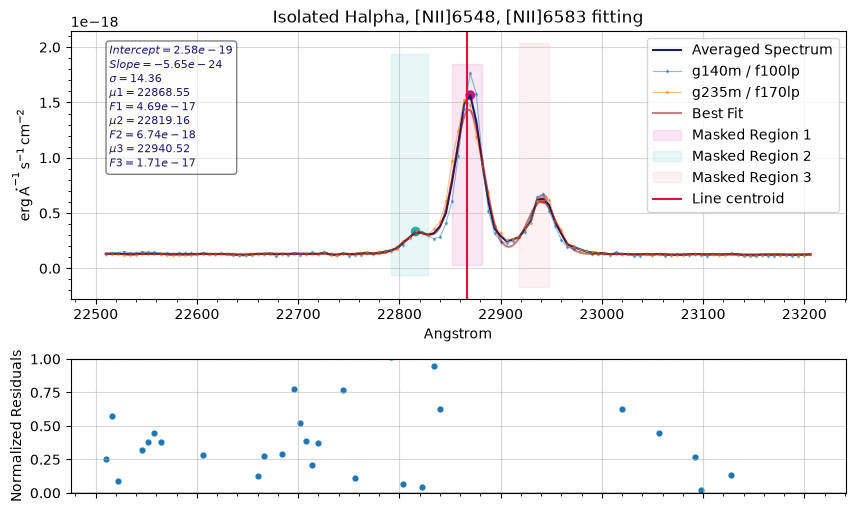

1Hbeta
Line: 1Hbeta 

Redshift: 2.4837361 

Rest window: 4783.18 Angstrom -- 4933.44 Angstrom 

Observed window: 16663.336838798 Angstrom -- 17186.803025184 Angstrom 

Spectrum range: 5500.0 Angstrom -- 55102.00000000372 Angstrom 

Points selected: 87 

Selected wavelength range: 16666.000000000837 Angstrom -- 17182.000000000877 Angstrom 

Finite wavelengths: 87 

Finite fluxes: 87 

g140m / f100lp: 87 finite samples
g235m / f170lp: 87 finite samples


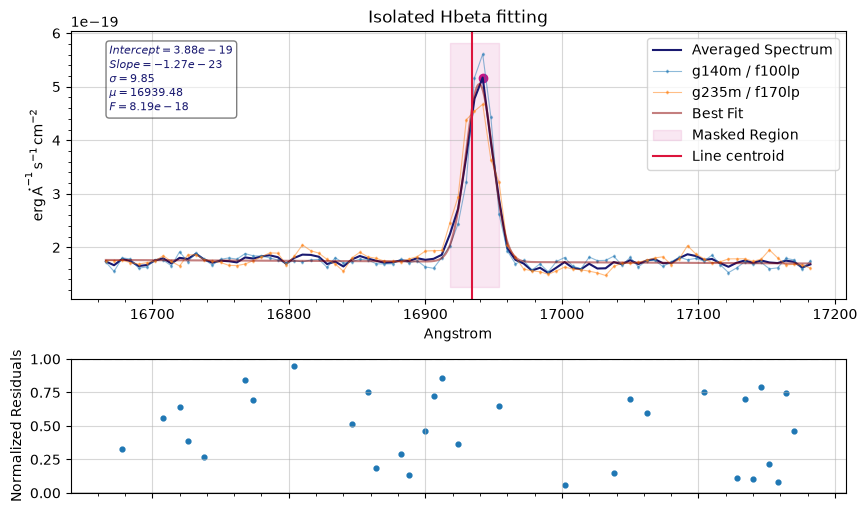

1[OI]6300
Line: 1[OI]6300 

Redshift: 2.4837361 

Rest window: 6052.36 Angstrom -- 6510.87 Angstrom 

Observed window: 21084.825022195997 Angstrom -- 22682.152861406998 Angstrom 

Spectrum range: 5500.0 Angstrom -- 55102.00000000372 Angstrom 

Points selected: 266 

Selected wavelength range: 21088.000000001168 Angstrom -- 22678.00000000129 Angstrom 

Finite wavelengths: 266 

Finite fluxes: 266 

g140m / f100lp: 266 finite samples
g235m / f170lp: 266 finite samples


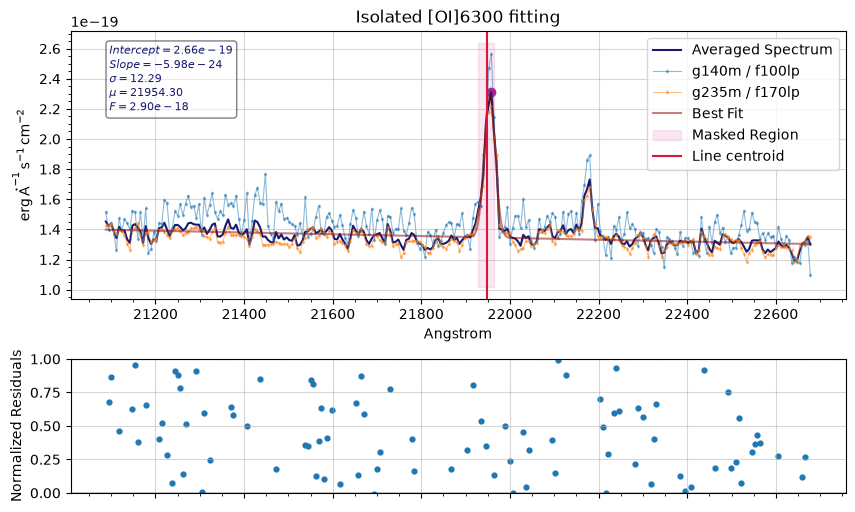

1[OII]3727
Line: 1[OII]3727 

Redshift: 2.4837361 

Rest window: 3576.39 Angstrom -- 3851.5 Angstrom 

Observed window: 12459.198950679 Angstrom -- 13417.609589149999 Angstrom 

Spectrum range: 5500.0 Angstrom -- 55102.00000000372 Angstrom 

Points selected: 160 

Selected wavelength range: 12460.000000000522 Angstrom -- 13414.000000000593 Angstrom 

Finite wavelengths: 160 

Finite fluxes: 135 

g140m / f100lp: 160 finite samples


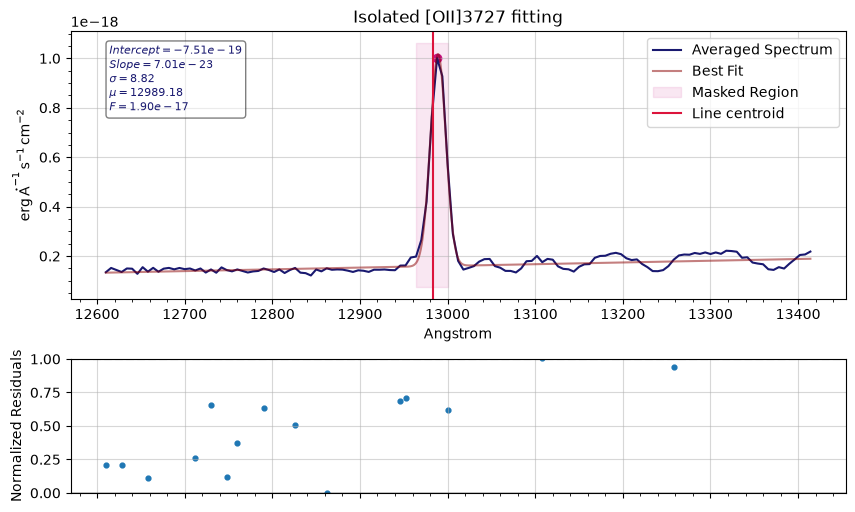

2[OII]7322, [OII]7332
Line: 2[OII]7322, [OII]7332 

Redshift: 2.4837361 

Rest window: 7152.79 Angstrom -- 7450.82 Angstrom 

Observed window: 24918.432738719 Angstrom -- 25956.690608602 Angstrom 

Spectrum range: 5500.0 Angstrom -- 55102.00000000372 Angstrom 

Points selected: 173 

Selected wavelength range: 24922.00000000145 Angstrom -- 25954.000000001535 Angstrom 

Finite wavelengths: 173 

Finite fluxes: 173 

g140m / f100lp: 173 finite samples
g235m / f170lp: 173 finite samples


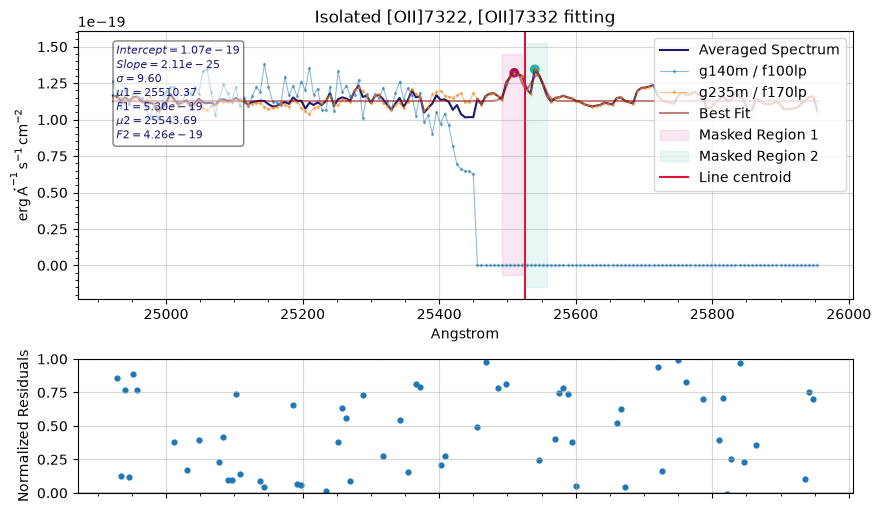

2Hgamma, [OIII]4364
Line: 2Hgamma, [OIII]4364 

Redshift: 2.4837361 

Rest window: 4264.16 Angstrom -- 4424.64 Angstrom 

Observed window: 14855.208128175998 Angstrom -- 15414.278097504 Angstrom 

Spectrum range: 5500.0 Angstrom -- 55102.00000000372 Angstrom 

Points selected: 93 

Selected wavelength range: 14860.000000000702 Angstrom -- 15412.000000000742 Angstrom 

Finite wavelengths: 93 

Finite fluxes: 93 

g140m / f100lp: 93 finite samples


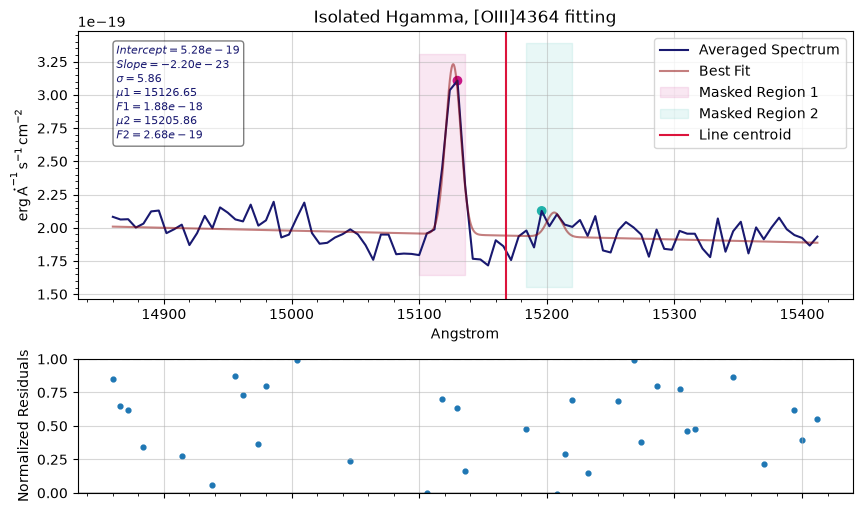

1[OIII]4959
Line: 1[OIII]4959 

Redshift: 2.4837361 

Rest window: 4908.4 Angstrom -- 4993.54 Angstrom 

Observed window: 17099.57027324 Angstrom -- 17396.175564793997 Angstrom 

Spectrum range: 5500.0 Angstrom -- 55102.00000000372 Angstrom 

Points selected: 49 

Selected wavelength range: 17104.00000000087 Angstrom -- 17392.00000000089 Angstrom 

Finite wavelengths: 49 

Finite fluxes: 49 

g140m / f100lp: 49 finite samples
g235m / f170lp: 49 finite samples


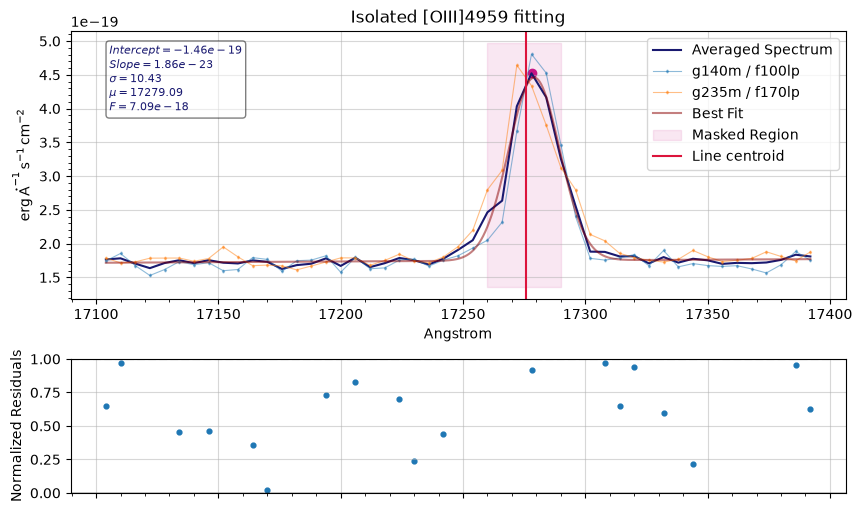

1[OIII]5007
Line: 1[OIII]5007 

Redshift: 2.4837361 

Rest window: 4974.76 Angstrom -- 5058.65 Angstrom 

Observed window: 17330.751000836 Angstrom -- 17623.001622264997 Angstrom 

Spectrum range: 5500.0 Angstrom -- 55102.00000000372 Angstrom 

Points selected: 49 

Selected wavelength range: 17332.000000000888 Angstrom -- 17620.00000000091 Angstrom 

Finite wavelengths: 49 

Finite fluxes: 49 

g140m / f100lp: 49 finite samples
g235m / f170lp: 49 finite samples


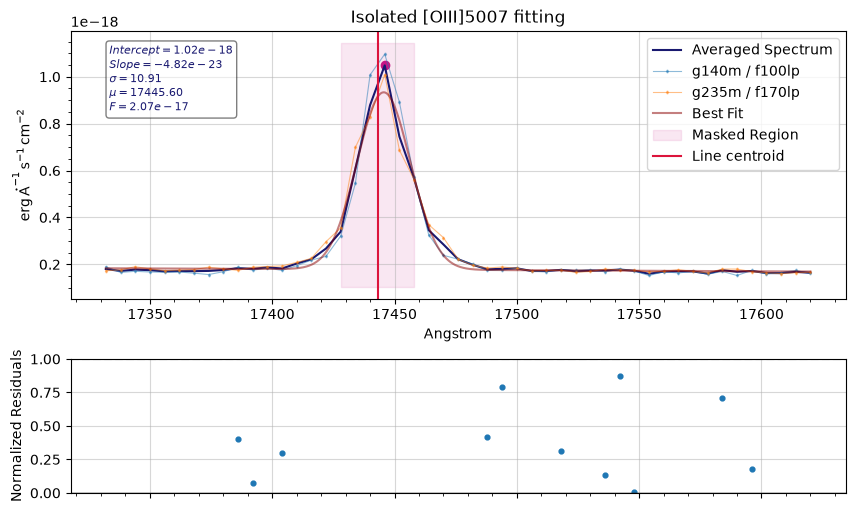

2[SII]6717, [SII]6731
Line: 2[SII]6717, [SII]6731 

Redshift: 2.4837361 

Rest window: 6602.58 Angstrom -- 6877.68 Angstrom 

Observed window: 23001.646299138 Angstrom -- 23960.022100248 Angstrom 

Spectrum range: 5500.0 Angstrom -- 55102.00000000372 Angstrom 

Points selected: 160 

Selected wavelength range: 23002.00000000131 Angstrom -- 23956.000000001386 Angstrom 

Finite wavelengths: 160 

Finite fluxes: 160 

g140m / f100lp: 160 finite samples
g235m / f170lp: 160 finite samples


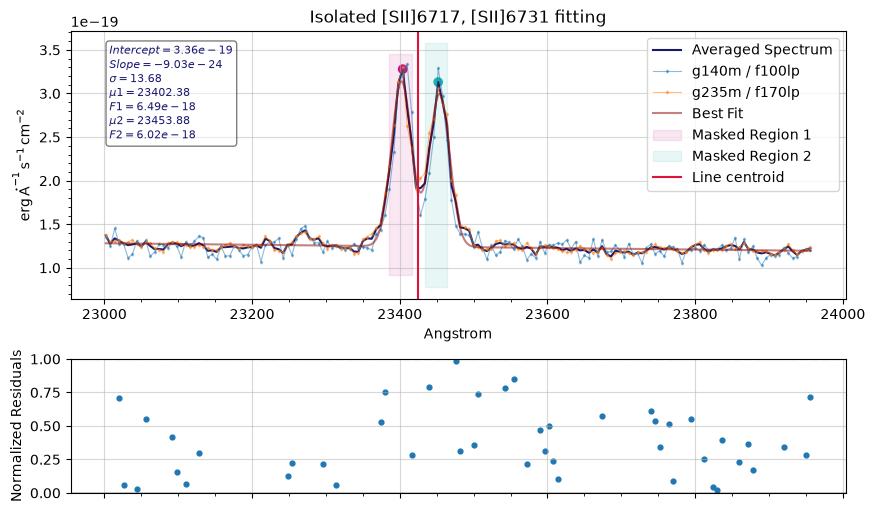

Density estimates:

461.82760485676073 514.1126191493918 568.8693113677206

Te O+ estimates:

45949.838358452995 63650.96525798685 86527.72864079749

Te O2+ estimates:

10734.563020635222 12720.077974805314 14405.027251522932 

Te O+ empirical estimates:

10514.194114444654 11904.054582363719 13083.519076066052 

Stack has 12+log(O/H) = 7.94 (7.79-8.16) 


⊹₊˚‧︵‿₊⊱·✶·⊰₊‿︵‧˚₊⊹₊˚‧︵‿₊⊱·✶·⊰₊‿︵‧˚₊⊹


In [4]:
test = collection_metallicity(["aurora-gdn02-v4_g395m-f290lp_1914_26798.spec.fits"])

In [9]:
test['aurora-gdn02-v4_g395m-f290lp_1914_26798.spec.fits']['fits']['Hgamma, [OIII]4364']

[{'element': 'Hgamma, [OIII]4364',
  'lines': '2',
  'intercept': 5.276781777653056e-19,
  'slope': -2.1992660919401603e-23,
  'sigma': 5.861967914320871,
  'mean1': 15126.648393642985,
  'flux1': 1.8825513346690906e-18,
  'mean2': 15205.857634256763,
  'flux2': 2.6780540159868095e-19},
 {'intercept': 8.461002601120164e-20,
  'slope': 5.589514909206063e-24,
  'sigma': 0.4622827265294636,
  'mean1': 0.48072220807060195,
  'flux1': 1.3538022566457222e-19,
  'mean2': 3.0522797814661997,
  'flux2': 1.0336606363778714e-19}]